# Mars Landform Classification using Custom CNN

Custom CNN trained from scratch on 8-class Mars surface landform dataset.

## 1. Import Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import time

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

print(f'PyTorch version: {torch.__version__}')
print(f'Torchvision version: {torchvision.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'CUDA device: {torch.cuda.get_device_name(0)}')

PyTorch version: 2.10.0+cu128
Torchvision version: 0.25.0+cu128
CUDA available: True
CUDA device: Tesla T4


## 2. Configuration

In [2]:
BASE = '/kaggle/input/datasets/qasimchaudry/hirise-mars-surface-image-datasets'

dataset_dirs = [
    f'{BASE}/hirise-map-proj-v3_2/hirise-map-proj-v3_2/map-proj-v3_2',
    f'{BASE}/hirise-map-proj-v3/hirise-map-proj-v3/map-proj-v3',
]
labels_file = f'{BASE}/hirise-map-proj-v3_2/hirise-map-proj-v3_2/labels-map-proj_v3_2_train_val_test.txt'

class_names = [
    'other',
    'crater',
    'dark dune',
    'slope streak',
    'bright dune',
    'impact ejecta',
    'swiss cheese',
    'spider'
]
num_classes = len(class_names)

image_size = 224
# batch size scaled for two t4s (32 per gpu)
batch_size = 64
num_epochs = 50
learning_rate = 0.001
# 2 workers per gpu
num_workers = 4
weight_decay = 1e-4
early_stopping_patience = 15

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
num_gpus = torch.cuda.device_count()
print(f'using device: {device}')
print(f'gpus available: {num_gpus}')
for i in range(num_gpus):
    print(f'  gpu {i}: {torch.cuda.get_device_name(i)}')

model_save_path = 'best_mars_customcnn_model.pth'
inference_config_path = 'customcnn_inference_config.json'


using device: cuda
gpus available: 2
  gpu 0: Tesla T4
  gpu 1: Tesla T4


## 3. Load Dataset

In [3]:
# Load labels file
df = pd.read_csv(labels_file, sep=' ', header=None, names=['filename', 'label', 'split'])
print(f'Total samples: {len(df)}')
print(f'\nSplit distribution:')
print(df['split'].value_counts())
print(f'\nClass distribution:')
print(df['label'].value_counts().sort_index())

Total samples: 67810

Split distribution:
split
train    51058
val      14959
test      1793
Name: count, dtype: int64

Class distribution:
label
0    52722
1     5857
2      857
3     1603
4     1654
5      777
6     2772
7     1568
Name: count, dtype: int64


In [4]:
# Function to find image path across multiple directories
def find_image_path(filename, dataset_dirs):
    for base_dir in dataset_dirs:
        full_path = os.path.join(base_dir, filename)
        if os.path.exists(full_path):
            return full_path
    return None

# Verify images exist and filter dataset
valid_indices = []
for idx, row in df.iterrows():
    if find_image_path(row['filename'], dataset_dirs) is not None:
        valid_indices.append(idx)

df = df.loc[valid_indices].reset_index(drop=True)
print(f'Valid samples: {len(df)}')

# Split data
train_df = df[df['split'] == 'train'].reset_index(drop=True)
val_df = df[df['split'] == 'val'].reset_index(drop=True)
test_df = df[df['split'] == 'test'].reset_index(drop=True)

print(f'\nTrain samples: {len(train_df)}')
print(f'Validation samples: {len(val_df)}')
print(f'Test samples: {len(test_df)}')

Valid samples: 67810

Train samples: 51058
Validation samples: 14959
Test samples: 1793


## 4. Calculate Class Weights

In [5]:
# Calculate class weights for balanced training
train_class_counts = np.bincount(train_df['label'].values, minlength=num_classes)
total_samples = len(train_df)
class_weights = total_samples / (num_classes * (train_class_counts + 1e-6))
class_weights = torch.FloatTensor(class_weights).to(device)

print('Class weights:')
for i, (name, weight) in enumerate(zip(class_names, class_weights.cpu().numpy())):
    print(f'  {name}: {weight:.4f}')

Class weights:
  other: 0.1595
  crater: 1.4729
  dark dune: 9.9103
  slope streak: 6.8041
  bright dune: 4.0886
  impact ejecta: 11.8409
  swiss cheese: 3.3276
  spider: 5.7706


## 5. Define Dataset Class

In [6]:
class MarsDataset(Dataset):
    def __init__(self, dataframe, dataset_dirs, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.dataset_dirs = dataset_dirs
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]
        filename = row['filename']
        label = row['label']

        img_path = find_image_path(filename, self.dataset_dirs)
        image = Image.open(img_path).convert('RGB')

        if self.transform:
            image = self.transform(image)

        return image, label

print('Dataset class defined')

Dataset class defined


## 6. Define Data Transforms

In [7]:
# ImageNet normalization
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

# Training transforms with augmentation
train_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

# Validation/test transforms without augmentation
val_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

print('Transforms defined')

Transforms defined


## 7. Create DataLoaders

In [8]:
train_dataset = MarsDataset(train_df, dataset_dirs, transform=train_transform)
val_dataset = MarsDataset(val_df, dataset_dirs, transform=val_transform)
test_dataset = MarsDataset(test_df, dataset_dirs, transform=val_transform)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,
                          num_workers=num_workers, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False,
                        num_workers=num_workers, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False,
                         num_workers=num_workers, pin_memory=True)

print(f'train batches: {len(train_loader)}')
print(f'validation batches: {len(val_loader)}')
print(f'test batches: {len(test_loader)}')


train batches: 798
validation batches: 234
test batches: 29


## 8. Custom CNN Architecture

In [9]:
class CustomCNN(nn.Module):
    def __init__(self, num_classes=8):
        super(CustomCNN, self).__init__()

        self.features = nn.Sequential(
            # Block 1: 224 -> 112
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.25),

            # Block 2: 112 -> 56
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.25),

            # Block 3: 56 -> 28
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.25),

            # Block 4: 28 -> 14
            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True),
            nn.Conv2d(512, 512, kernel_size=3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.25),

            # Block 5: 14 -> 7
            nn.Conv2d(512, 512, kernel_size=3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.25)
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(512, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

print('Custom CNN architecture defined')

Custom CNN architecture defined


## 9. Initialize Model, Loss and Optimizer

In [10]:
model = CustomCNN(num_classes)

# wrap in dataparallel if multiple gpus are available
if num_gpus > 1:
    model = nn.DataParallel(model)
    print(f'using dataparallel across {num_gpus} gpus')

model = model.to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f'total parameters: {total_params:,}')
print(f'trainable parameters: {trainable_params:,}')

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)

print('loss: crossentropyloss with class weights')
print(f'optimizer: adam lr={learning_rate}')


using dataparallel across 2 gpus
total parameters: 7,183,432
trainable parameters: 7,183,432
loss: crossentropyloss with class weights
optimizer: adam lr=0.001


## 10. Training and Validation Functions

In [11]:
def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    return running_loss / total, correct / total


def validate_epoch(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

    return running_loss / total, correct / total

print('Training functions defined')

Training functions defined


## 11. Train Model

In [12]:
import copy

history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_val_acc = 0.0
epochs_no_improve = 0
best_model_wts = copy.deepcopy(model.state_dict())

print(f'starting training for {num_epochs} epochs')
start_time = time.time()

for epoch in range(num_epochs):
    epoch_start = time.time()

    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = validate_epoch(model, val_loader, criterion, device)

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    epoch_time = time.time() - epoch_start

    print(f'epoch [{epoch+1}/{num_epochs}] ({epoch_time:.1f}s)')
    print(f'  train loss: {train_loss:.4f}, acc: {train_acc:.4f}')
    print(f'  val loss: {val_loss:.4f}, acc: {val_acc:.4f}')

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        epochs_no_improve = 0
        best_model_wts = copy.deepcopy(model.state_dict())
        # save module weights directly (unwrap dataparallel if needed)
        weights_to_save = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
        torch.save(weights_to_save, model_save_path)
        print(f'  model saved with val_acc: {val_acc:.4f}')
    else:
        epochs_no_improve += 1
        print(f'  no improvement ({epochs_no_improve}/{early_stopping_patience})')

    if epochs_no_improve >= early_stopping_patience:
        print(f'early stopping triggered after {epoch+1} epochs')
        break

total_time = time.time() - start_time
print(f'\ntraining completed in {total_time:.1f}s')
print(f'best validation accuracy: {best_val_acc:.4f}')

# load best weights back into model
if isinstance(model, nn.DataParallel):
    model.module.load_state_dict(torch.load(model_save_path, weights_only=True))
else:
    model.load_state_dict(torch.load(model_save_path, weights_only=True))
print('best model weights loaded')


starting training for 50 epochs
epoch [1/50] (461.0s)
  train loss: 1.8709, acc: 0.1011
  val loss: 1.9715, acc: 0.0556
  model saved with val_acc: 0.0556
epoch [2/50] (410.3s)
  train loss: 1.8350, acc: 0.0801
  val loss: 1.9877, acc: 0.0769
  model saved with val_acc: 0.0769
epoch [3/50] (410.7s)
  train loss: 1.8352, acc: 0.0789
  val loss: 2.0564, acc: 0.0943
  model saved with val_acc: 0.0943
epoch [4/50] (409.8s)
  train loss: 1.8399, acc: 0.0825
  val loss: 1.9119, acc: 0.0945
  model saved with val_acc: 0.0945
epoch [5/50] (410.2s)
  train loss: 1.8320, acc: 0.0946
  val loss: 2.1259, acc: 0.0999
  model saved with val_acc: 0.0999
epoch [6/50] (410.0s)
  train loss: 1.8296, acc: 0.0676
  val loss: 2.0115, acc: 0.0492
  no improvement (1/15)
epoch [7/50] (410.3s)
  train loss: 1.8202, acc: 0.0817
  val loss: 1.9840, acc: 0.0505
  no improvement (2/15)
epoch [8/50] (410.3s)
  train loss: 1.8109, acc: 0.0884
  val loss: 2.0101, acc: 0.0454
  no improvement (3/15)
epoch [9/50] (410

## 11b. Save Inference Metadata

In [13]:
import json

# save class labels and preprocessing config for inference
inference_config = {
    'class_names': class_names,
    'image_size': image_size,
    'mean': mean,
    'std': std,
    'num_classes': num_classes
}
with open(inference_config_path, 'w') as f:
    json.dump(inference_config, f, indent=2)

print(f'inference config saved to {inference_config_path}')


inference config saved to customcnn_inference_config.json


## 12. Plot Training History

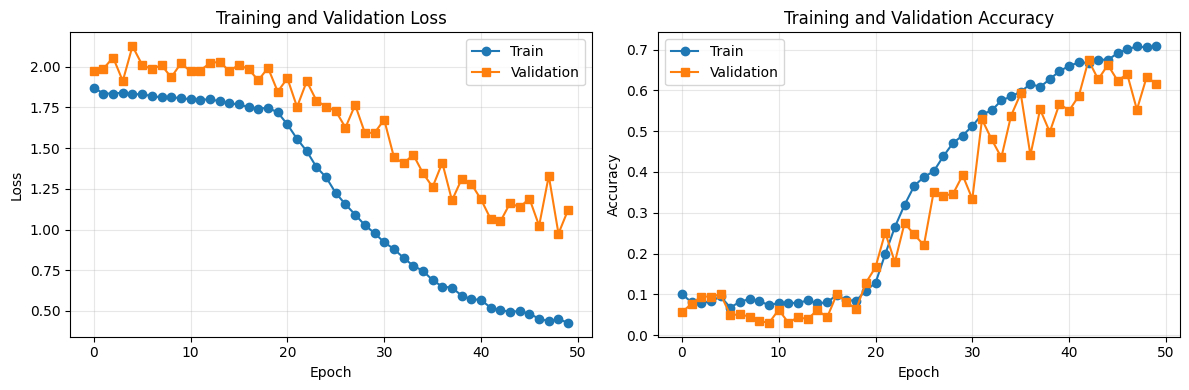

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(history['train_loss'], label='Train', marker='o')
ax1.plot(history['val_loss'], label='Validation', marker='s')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('Training and Validation Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(history['train_acc'], label='Train', marker='o')
ax2.plot(history['val_acc'], label='Validation', marker='s')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.set_title('Training and Validation Accuracy')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 13. Test Evaluation

In [15]:
# unwrap dataparallel for clean eval
eval_model = model.module if isinstance(model, nn.DataParallel) else model
eval_model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = eval_model(images)
        _, predicted = outputs.max(1)

        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)

print('test evaluation completed')
print(f'total test samples: {len(all_labels)}')


test evaluation completed
total test samples: 1793


## 14. Calculate Metrics

In [16]:
test_accuracy = accuracy_score(all_labels, all_predictions)
test_precision = precision_score(all_labels, all_predictions, average='weighted', zero_division=0)
test_recall = recall_score(all_labels, all_predictions, average='weighted', zero_division=0)
test_f1 = f1_score(all_labels, all_predictions, average='weighted', zero_division=0)

print('Test Set Performance:')
print(f'Accuracy:  {test_accuracy:.4f}')
print(f'Precision: {test_precision:.4f}')
print(f'Recall:    {test_recall:.4f}')
print(f'F1-Score:  {test_f1:.4f}')

Test Set Performance:
Accuracy:  0.6715
Precision: 0.8530
Recall:    0.6715
F1-Score:  0.7305


## 15. Classification Report

In [17]:
print('Classification Report:')
print(classification_report(all_labels, all_predictions, target_names=class_names, zero_division=0))

Classification Report:
               precision    recall  f1-score   support

        other       0.97      0.68      0.80      1482
       crater       0.33      0.65      0.44        89
    dark dune       0.30      0.89      0.45        66
 slope streak       0.26      0.45      0.33        49
  bright dune       0.81      0.81      0.81        16
impact ejecta       0.02      0.29      0.03         7
 swiss cheese       0.42      0.88      0.57        42
       spider       0.04      0.07      0.05        42

     accuracy                           0.67      1793
    macro avg       0.39      0.59      0.44      1793
 weighted avg       0.85      0.67      0.73      1793



## 16. Confusion Matrix

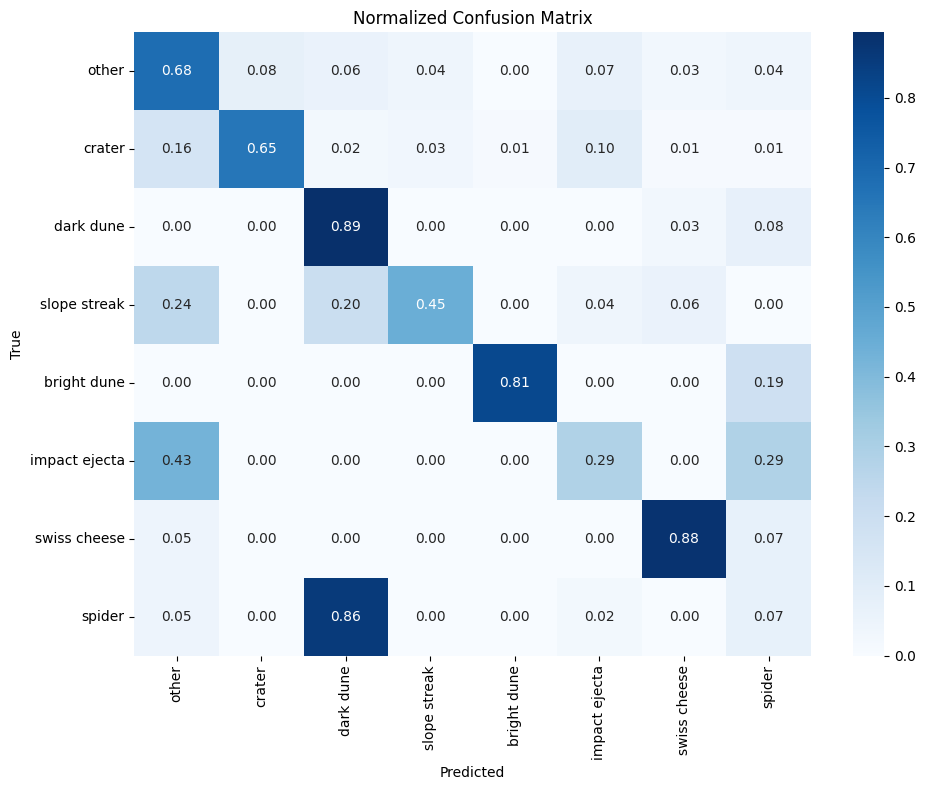

In [18]:
cm = confusion_matrix(all_labels, all_predictions)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(10, 8))
sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Normalized Confusion Matrix')
plt.tight_layout()
plt.show()

## 17. Per-Class Performance

In [19]:
per_class_precision = precision_score(all_labels, all_predictions, average=None, zero_division=0)
per_class_recall = recall_score(all_labels, all_predictions, average=None, zero_division=0)
per_class_f1 = f1_score(all_labels, all_predictions, average=None, zero_division=0)

print('Per-Class Performance:')
for i, name in enumerate(class_names):
    print(f'{name}:')
    print(f'  Precision: {per_class_precision[i]:.4f}')
    print(f'  Recall:    {per_class_recall[i]:.4f}')
    print(f'  F1-Score:  {per_class_f1[i]:.4f}')

Per-Class Performance:
other:
  Precision: 0.9684
  Recall:    0.6815
  F1-Score:  0.8000
crater:
  Precision: 0.3277
  Recall:    0.6517
  F1-Score:  0.4361
dark dune:
  Precision: 0.3026
  Recall:    0.8939
  F1-Score:  0.4521
slope streak:
  Precision: 0.2619
  Recall:    0.4490
  F1-Score:  0.3308
bright dune:
  Precision: 0.8125
  Recall:    0.8125
  F1-Score:  0.8125
impact ejecta:
  Precision: 0.0177
  Recall:    0.2857
  F1-Score:  0.0333
swiss cheese:
  Precision: 0.4205
  Recall:    0.8810
  F1-Score:  0.5692
spider:
  Precision: 0.0390
  Recall:    0.0714
  F1-Score:  0.0504


## 18. Sample Predictions

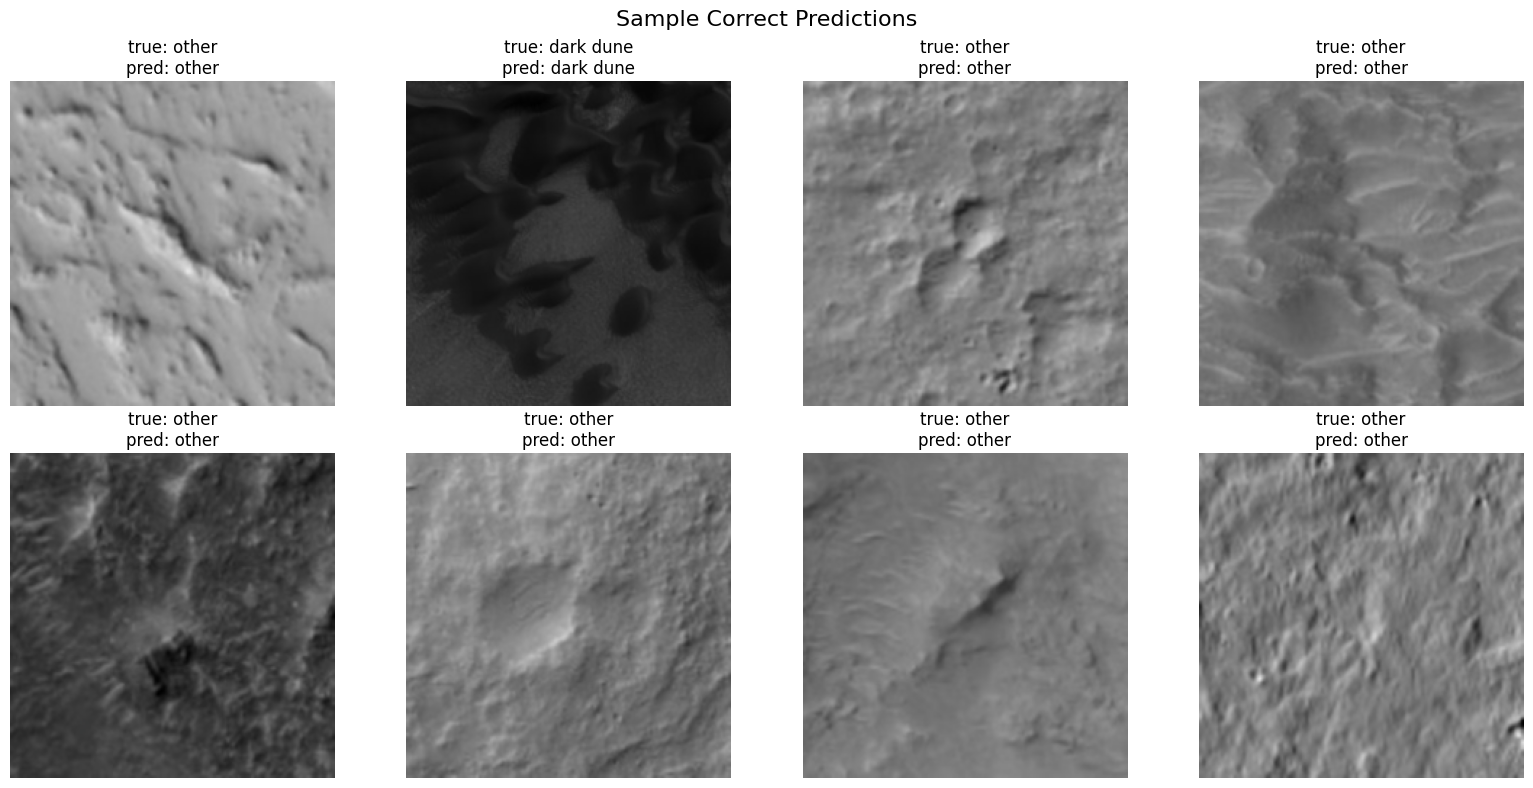

In [20]:
def denormalize_image(tensor, mean, std):
    tensor = tensor.clone()
    for t, m, s in zip(tensor, mean, std):
        t.mul_(s).add_(m)
    return torch.clamp(tensor, 0, 1)


# Sample correct predictions
correct_indices = np.where(all_predictions == all_labels)[0]
sample_correct = np.random.choice(correct_indices, min(8, len(correct_indices)), replace=False)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for idx, sample_idx in enumerate(sample_correct):
    img, label = test_dataset[sample_idx]
    img_denorm = denormalize_image(img, mean, std)
    img_denorm = img_denorm.numpy().transpose((1, 2, 0))

    pred_label = all_predictions[sample_idx]

    axes[idx].imshow(img_denorm)
    axes[idx].set_title(f'true: {class_names[label]}\npred: {class_names[pred_label]}')
    axes[idx].axis('off')

plt.suptitle('Sample Correct Predictions', fontsize=16)
plt.tight_layout()
plt.show()

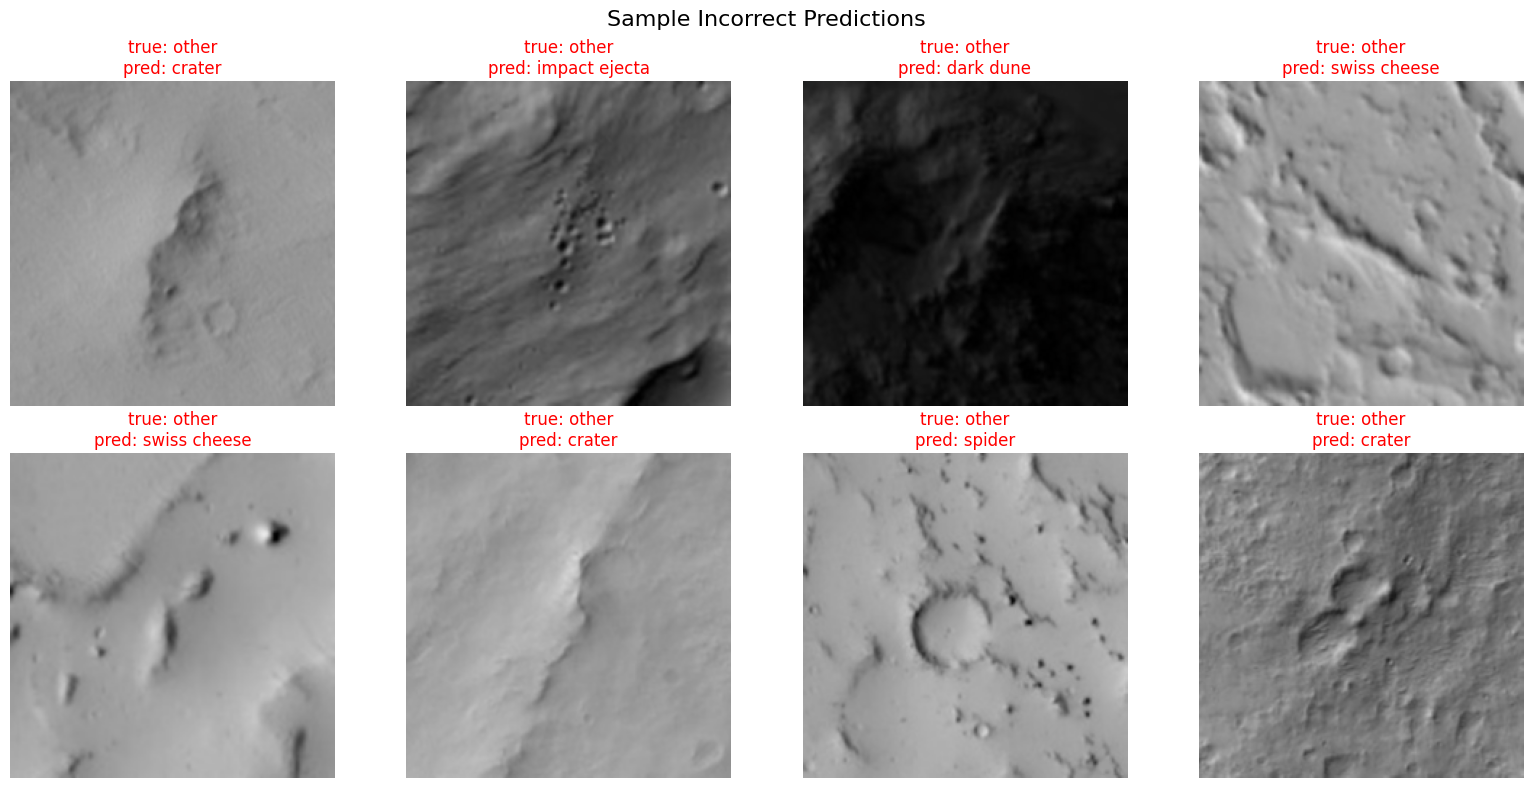

In [21]:
# Sample incorrect predictions
incorrect_indices = np.where(all_predictions != all_labels)[0]

if len(incorrect_indices) > 0:
    sample_incorrect = np.random.choice(incorrect_indices, min(8, len(incorrect_indices)), replace=False)

    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.flatten()

    for idx, sample_idx in enumerate(sample_incorrect):
        img, label = test_dataset[sample_idx]
        img_denorm = denormalize_image(img, mean, std)
        img_denorm = img_denorm.numpy().transpose((1, 2, 0))

        pred_label = all_predictions[sample_idx]

        axes[idx].imshow(img_denorm)
        axes[idx].set_title(f'true: {class_names[label]}\npred: {class_names[pred_label]}', color='red')
        axes[idx].axis('off')

    plt.suptitle('Sample Incorrect Predictions', fontsize=16)
    plt.tight_layout()
    plt.show()
else:
    print('No incorrect predictions found')

## 19. Summary

In [22]:
print('Model Training Summary')
print(f'Architecture: Custom CNN (trained from scratch)')
print(f'Total parameters: {total_params:,}')
print(f'Trainable parameters: {trainable_params:,}')
print()
print(f'Training configuration:')
print(f'  Image size: {image_size}x{image_size}')
print(f'  Batch size: {batch_size}')
print(f'  Epochs: {num_epochs}')
print(f'  Learning rate: {learning_rate}')
print(f'  Early stopping patience: {early_stopping_patience}')
print()
print(f'Dataset splits:')
print(f'  Training: {len(train_df)} samples')
print(f'  Validation: {len(val_df)} samples')
print(f'  Test: {len(test_df)} samples')
print()
print(f'Best validation accuracy: {best_val_acc:.4f}')
print()
print(f'Test set performance:')
print(f'  Accuracy:  {test_accuracy:.4f}')
print(f'  Precision: {test_precision:.4f}')
print(f'  Recall:    {test_recall:.4f}')
print(f'  F1-Score:  {test_f1:.4f}')

Model Training Summary
Architecture: Custom CNN (trained from scratch)
Total parameters: 7,183,432
Trainable parameters: 7,183,432

Training configuration:
  Image size: 224x224
  Batch size: 64
  Epochs: 50
  Learning rate: 0.001
  Early stopping patience: 15

Dataset splits:
  Training: 51058 samples
  Validation: 14959 samples
  Test: 1793 samples

Best validation accuracy: 0.6738

Test set performance:
  Accuracy:  0.6715
  Precision: 0.8530
  Recall:    0.6715
  F1-Score:  0.7305
